El obejtivo de este trabajo será clasificar Pokémon de tipo Fuego y Agua mediante sus estadísticas, utilizando SVM, árboles de decisión y una red neuronal artificial.
El desarrollo sería:
1. Seleccionar Pokémon de tipo Fuego y Agua.
2. Utilizar sus seis estadísticas como variables de entrada.
3. Codificar el tipo como variable binaria.
4. Normalizar las estadísticas.
5. Dividir los datos en entrenamiento, validación y test.
6. Construir una red neuronal MLP con Keras.
7. Entrenar la red y analizar su evolución.
8. Evaluar su rendimiento con accuracy, precision, recall y F1-score.
9. Representar la matriz de confusión.
10. Analizar las conclusiones.

In [1]:
#hola david, espero que estés viendo esto. aquí voy a hacer las cosas del trabajo.

#hola Luve, soy megaretrasado


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos

#Directorio de Luve (Cuando lo vayas a usar Lucía, descomenta el tuyo y comenta el mío)

#df = pd.read_csv(r'C:\Users\PC\4º\Biofísica\trabajobio\trabajobio\archive\Pokemon.csv')

#Directorio de David

df = pd.read_csv(r'C:\Users\david\OneDrive - Universidade de Santiago de Compostela\4º Curso\Biofísica\Primer trabajo (ahora sí)\trabajobio\archive\Pokemon.csv')

# Información general
print(f"Total de Pokémon: {df.shape[0]}")
print(f"Total de variables: {df.shape[1]}")

print("\nColumnas del dataset:")
print(df.columns.tolist())

print("\nNúmero de Pokémon de cada tipo:")
print(df[['Type 1','Type 2']].stack().value_counts())

print('\n''=' * 50)
print(f'\n Número de Pokémon legendarios: {df["Legendary"].sum()}')
print(f'\n Número de Pokémon no legendarios: {df.shape[0] - df["Legendary"].sum()}')

# Mostramos las primeras filas
display(df.head())

Total de Pokémon: 800
Total de variables: 13

Columnas del dataset:
['#', 'Name', 'Type 1', 'Type 2', 'Total', 'HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed', 'Generation', 'Legendary']

Número de Pokémon de cada tipo:
Water       126
Normal      102
Flying      101
Grass        95
Psychic      90
Bug          72
Ground       67
Fire         64
Poison       62
Rock         58
Fighting     53
Dark         51
Dragon       50
Electric     50
Steel        49
Ghost        46
Fairy        40
Ice          38
Name: count, dtype: int64

=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=

 Número de Pokémon legendarios: 65

 Número de Pokémon no legendarios: 735


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


## Preparación y limpieza de los datos

Antes de entrenar la red neuronal, es necesario preparar el conjunto de datos para garantizar que la información utilizada sea adecuada.

En esta etapa se comprobarán las dimensiones del dataset, los tipos de variables, la existencia de duplicados y los posibles valores ausentes.

Posteriormente, seleccionaremos únicamente los Pokémon cuyo tipo principal sea Fuego o Agua. Esta selección permitirá plantear un problema de clasificación binaria mediante una red neuronal artificial.

También se estudiará la distribución de las estadísticas y se analizarán las correlaciones entre las variables numéricas.

In [3]:
# Dimensiones iniciales
print("Dimensiones iniciales:", df.shape)

# Primeras filas
display(df.head())

# Información de las variables
df.info()

# Eliminación de duplicados
df = df.drop_duplicates()

print("\nDimensiones tras eliminar duplicados:", df.shape)

# Eliminación de valores perdidos
df = df.dropna()

print("\nDimensiones tras eliminar valores perdidos:", df.shape)


Dimensiones iniciales: (800, 13)


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        800 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp. Atk     800 non-null    int64
 9   Sp. Def     800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 75.9 KB

Dimensiones tras eliminar duplicados: (800, 13)

Dimensiones tras eliminar valores perdidos: (414, 13)


Vemos que se pierden algunas filas, es decir, algunos Pokemon. Aproximadamente la mitad. 


Pero vamos a ver ahora que lo que ocurre es que nos está eliminando los que solo tienen un tipo. Comprobémoslo.

In [ ]:
#Volvemos a cargar el archivo de origen

df = pd.read_csv(r'C:\Users\david\OneDrive - Universidade de Santiago de Compostela\4º Curso\Biofísica\Primer trabajo (ahora sí)\trabajobio\archive\Pokemon.csv')
#df = pd.read_csv(r'C:\Users\PC\4º\Biofísica\trabajobio\trabajobio\archive\Pokemon.csv')

print(df['Type 2'].unique())


print('\n' + '=' * 50)

restantes = df.shape[0] - df['Type 2'].isna().sum()
print(f"Número de Pokémon sin tipo secundario: {restantes}")


<StringArray>
[  'Poison',        nan,   'Flying',   'Dragon',   'Ground',    'Fairy',
    'Grass', 'Fighting',  'Psychic',    'Steel',      'Ice',     'Rock',
     'Dark',    'Water', 'Electric',     'Fire',    'Ghost',      'Bug',
   'Normal']
Length: 19, dtype: str

Número de Pokémon sin tipo secundario: 414




Como vemos, el número de pokemons que nos quedan son justamente  los que quedaban después de eliminar los nans. 


Para poder trabajar más cómodamente con los datos, vamos a sustituir los 'nan' por 'None'.



In [ ]:
df['Type 2'] = df['Type 2'].fillna('None')

print(df['Type 2'].unique())

<StringArray>
[  'Poison',     'None',   'Flying',   'Dragon',   'Ground',    'Fairy',
    'Grass', 'Fighting',  'Psychic',    'Steel',      'Ice',     'Rock',
     'Dark',    'Water', 'Electric',     'Fire',    'Ghost',      'Bug',
   'Normal']
Length: 19, dtype: str


## Escogemos las variables que vamos a utilizar

Como dijimos arriba, vamos a intentar predecir el tipo de pokemon en cuestión según sus estadísiticas, restringiéndonos solamente a clasificarlos en si son psíquico o si son lucha. Para ello, nuestra variable X van a ser todas las estadísticas del pokemon, mientras que la Y serán justamente sus tipos, pero quedándonos ya solo con los pokemon tipo psíquico y lucha.


In [3]:
# Variables que utilizaremos
estadísticas = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']

# Seleccionamos únicamente Pokémon de tipo Psíquico y Lucha
df_filtrado = df[df['Type 1'].isin(['Psychic', 'Fighting']) | df['Type 2'].isin(['Psychic', 'Fighting'])].copy()


# Creamos la variable objetivo
# 1 = Psychic
# 0 = Fighting

df_filtrado['target'] = ((df_filtrado['Type 1'] == 'Psychic') | (df_filtrado['Type 2'] == 'Psychic')).astype(int)

print("\nDistribución de las clases:")
print(df_filtrado[['Type 1','Type 2']].stack().value_counts())


print("\nNúmero de Pokémon seleccionados:", len(df_filtrado))

display(df_filtrado)


Distribución de las clases:
Psychic     90
Fighting    53
Fire        10
Steel       10
Water        8
Flying       7
Grass        6
Fairy        6
Dark         6
Normal       4
Dragon       4
Rock         3
Ice          2
Bug          2
Ground       2
Poison       2
Ghost        1
Name: count, dtype: int64

Número de Pokémon seleccionados: 137


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary,target
61,56,Mankey,Fighting,NaN,305,40,80,35,35,45,70,1,False,0
62,57,Primeape,Fighting,NaN,455,65,105,60,60,70,95,1,False,0
67,62,Poliwrath,Water,Fighting,510,90,95,95,70,90,70,1,False,0
68,63,Abra,Psychic,NaN,310,25,20,15,105,55,90,1,False,1
69,64,Kadabra,Psychic,NaN,400,40,35,30,120,70,105,1,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
756,686,Inkay,Dark,Psychic,288,53,54,53,37,46,45,6,False,1
757,687,Malamar,Dark,Psychic,482,86,92,88,68,75,73,6,False,1
771,701,Hawlucha,Fighting,Flying,500,78,92,75,74,63,118,6,False,0
797,720,HoopaHoopa Confined,Psychic,Ghost,600,80,110,60,150,130,70,6,True,1


## Distribución de las estadísticas

Vamos a ver un primer momento cómo se distribuyen las estadísitcas según sea tipo psíquico o lucha.

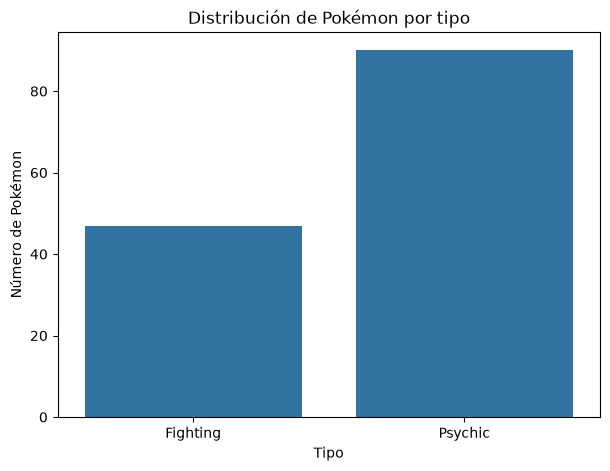

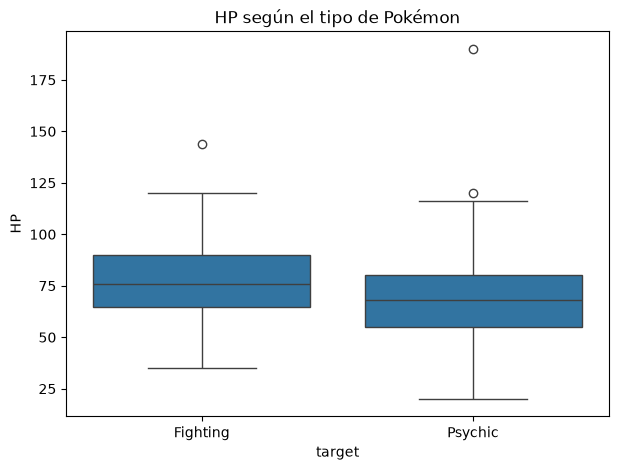

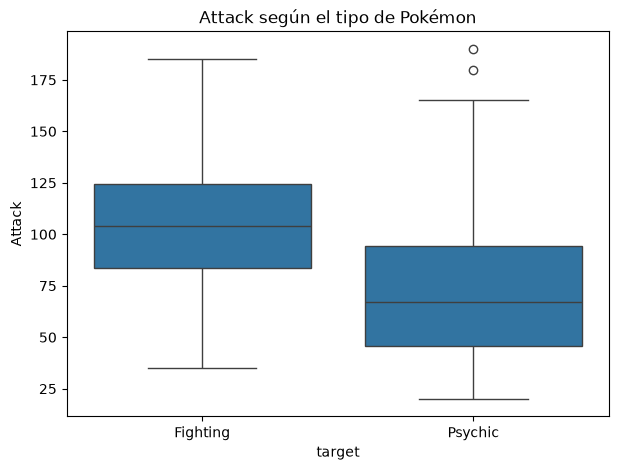

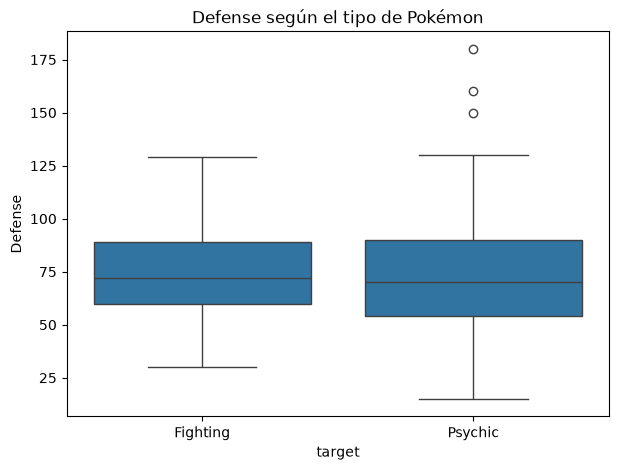

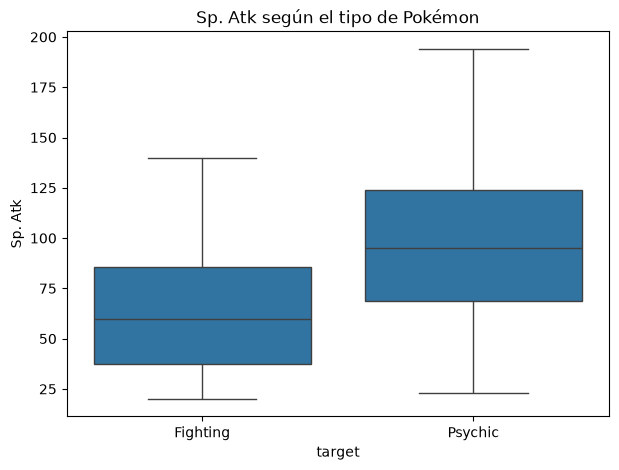

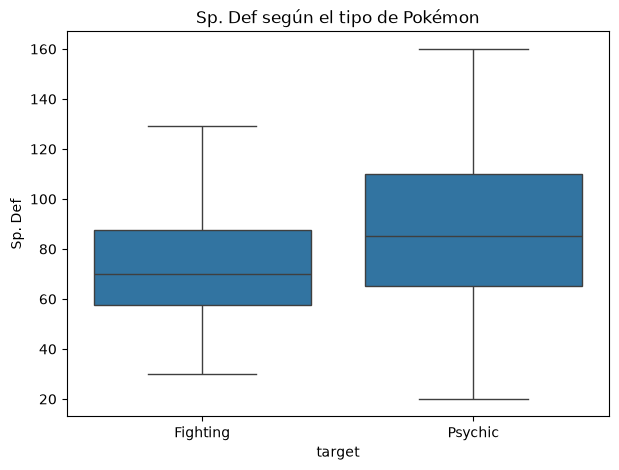

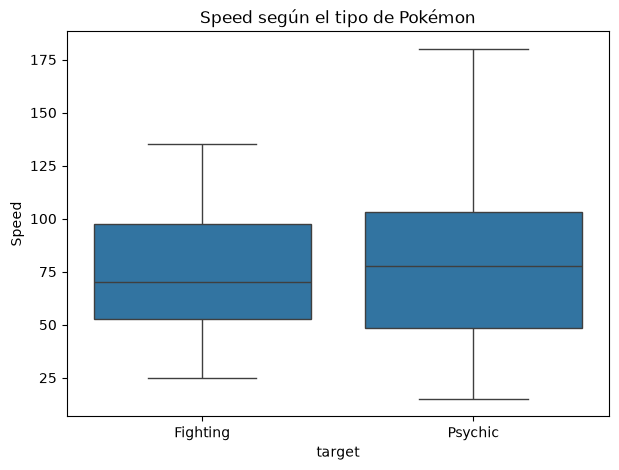

In [5]:
# Distribución de Pokémon por tipo
plt.figure(figsize=(7, 5))

sns.countplot(data=df_filtrado, x='target')

plt.title('Distribución de Pokémon por tipo')
plt.xticks([0, 1], ['Fighting', 'Psychic'])
plt.xlabel('Tipo')
plt.ylabel('Número de Pokémon')
plt.show()


# Comparación de las estadísticas según el tipo
for variable in estadísticas:

    plt.figure(figsize=(7, 5))

    sns.boxplot(data=df_filtrado, x='target', y=variable)
    plt.xticks([0, 1], ['Fighting', 'Psychic'])

    plt.title(f'{variable} según el tipo de Pokémon')
    plt.show()

## División y normalización de los datos
Para poder realizar el modelo de clasificación, necesitamos dividir nuestros datos en barios conjuntos. Primero, el conjunto de entrenamiento, que serán los datos a partir de los cuales el modelo intentará sacar una correlación para poder aplicar en los siguientes conjuntos. Este conjunto lo vamos a dividir en dos subconjuntos. Uno para entrenar el modelo y otro para hacer una primera comprobación.


Por último, vamos a escoger otro entrenamiento para ver cómo clasifica un nuevo conjunto

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variables predictoras
X = df_filtrado[estadísticas].values

# Variable objetivo
y = df_filtrado['target'].values

# Primera división: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# División del entrenamiento para obtener validación
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)

# Escalado de las variables
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Datos de entrenamiento:", X_train_scaled.shape)
print("Datos de validación:", X_val_scaled.shape)
print("Datos de prueba:", X_test_scaled.shape)

Datos de entrenamiento: (87, 6)
Datos de validación: (22, 6)
Datos de prueba: (28, 6)


## Construcción y entrenamiento de la red neuronal

In [34]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import SGD

from tensorflow.keras.callbacks import EarlyStopping

# Fijamos la semilla para reproducibilidad
np.random.seed(42) 
tf.random.set_seed(42)

# Creación de la red neuronal
model = keras.Sequential([layers.Dense(20, activation='relu', input_shape=(X_train_scaled.shape[1],)), layers.Dense(20, activation='relu'), layers.Dense(20, activation='relu'), layers.Dense(1, activation='sigmoid')])
#keras.sequential: Crea una red neuronal en la que las capas están organizadas consecutivamente. La información pasa de una capa a la siguiente.
#input_shape=(X_train_scaled.shape[1],): Especifica la forma de los datos de entrada. En este caso, el número de características (columnas) en los datos de entrenamiento escalados. (Indica que cada Pokémon tiene seis características de entrada.)
#layers.Dense(20, activation='relu'): Crea una capa densa (fully connected) con 20 neuronas y la función de activación ReLU (Rectified Linear Unit). Esta capa aprenderá patrones complejos a partir de las características de entrada.
#layer.dense(1, activation='sigmoid'): Crea la capa de salida con una sola neurona y la función de activación sigmoide. Esta capa produce un valor entre 0 y 1, que se interpreta como la probabilidad de que un Pokémon sea de tipo Psíquico (1) o Lucha (0).


# Compilación del modelo
sgd = SGD(learning_rate=0.01)

model.compile(optimizer=sgd, loss='binary_crossentropy', metrics=['accuracy'])
#SGD: algoritmo que modifica los pesos de la red para mejorar sus predicciones.
#Learning rate = 0.01: determina el tamaño de los cambios que realiza el algoritmo durante el aprendizaje.
#Binary crossentropy: función que mide el error de las predicciones en un problema de dos categorías.
#Accuracy: mide el porcentaje de predicciones correctas.

# Resumen de la arquitectura
model.summary()

c:\Users\david\anaconda3\envs\tensorflow_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 20)             │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,001 (3.91 KB)

 Trainable params: 1,001 (3.91 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
# Early Stopping para evitar sobreajuste
early_stop = EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True)

# Entrenamiento
print("Entrenando la red neuronal...")

history = model.fit(X_train_scaled, y_train, epochs=500, batch_size=10, validation_data=(X_val_scaled, y_val), callbacks=[early_stop], verbose=1)
#X_train_scaled: características de los Pokémon utilizados para entrenar.
#y_train: clasificación correcta de esos Pokémon.
#epochs=500: número máximo de veces que el modelo puede recorrer los datos de entrenamiento.
#batch_size=10: procesa los datos en grupos de diez ejemplos antes de actualizar los pesos.
#validation_data: proporciona los datos de validación para controlar el aprendizaje.

print("\n¡Entrenamiento completado!")

print("Número de épocas ejecutadas:", len(history.history['loss']))

Entrenando la red neuronal...
Epoch 1/500


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4483 - loss: 0.6958 - val_accuracy: 0.4091 - val_loss: 0.6808
Epoch 2/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5057 - loss: 0.6878 - val_accuracy: 0.5455 - val_loss: 0.6732
Epoch 3/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6092 - loss: 0.6804 - val_accuracy: 0.7727 - val_loss: 0.6661
Epoch 4/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6667 - loss: 0.6737 - val_accuracy: 0.8182 - val_loss: 0.6596
Epoch 5/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6782 - loss: 0.6676 - val_accuracy: 0.8636 - val_loss: 0.6537
Epoch 6/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6667 - loss: 0.6622 - val_accuracy: 0.8182 - val_loss: 0.6481
Epoch 7/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6897 - loss: 0.6572 - val_accuracy: 0.7727 - val_loss: 0.6430
Epoch 8/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7011 - loss: 0.6527 - val_accuracy: 0.7273 - val_loss: 0.6382
Epoch 9/500

In [36]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

# Predicciones de la red neuronal
y_prob = model.predict(X_test_scaled)

# Convertimos probabilidades en clases
y_hat_test = (y_prob >= 0.5).astype(int).ravel()

# Accuracy
print("Red Neuronal - Accuracy:", accuracy_score(y_test, y_hat_test))

# Informe de clasificación
print("\nInforme de clasificación:")

print(classification_report(y_test, y_hat_test, target_names=['Psychic', 'Fighting'], zero_division=0))

# Matriz de confusión
print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_hat_test))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Red Neuronal - Accuracy: 0.7857142857142857

Informe de clasificación:
              precision    recall  f1-score   support

     Psychic       1.00      0.40      0.57        10
    Fighting       0.75      1.00      0.86        18

    accuracy                           0.79        28
   macro avg       0.88      0.70      0.71        28
weighted avg       0.84      0.79      0.76        28


Matriz de confusión:
[[ 4  6]
 [ 0 18]]


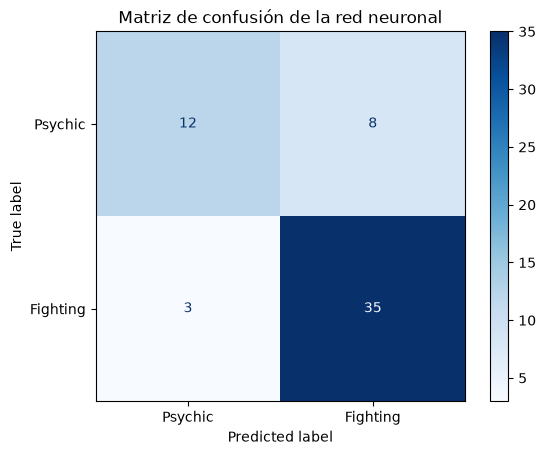

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_hat_test)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Psychic', 'Fighting'])

disp.plot(cmap='Blues')

plt.title('Matriz de confusión de la red neuronal')
plt.show()

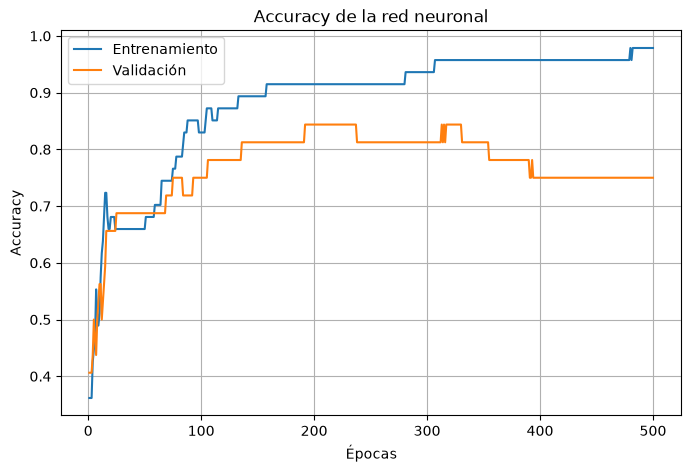

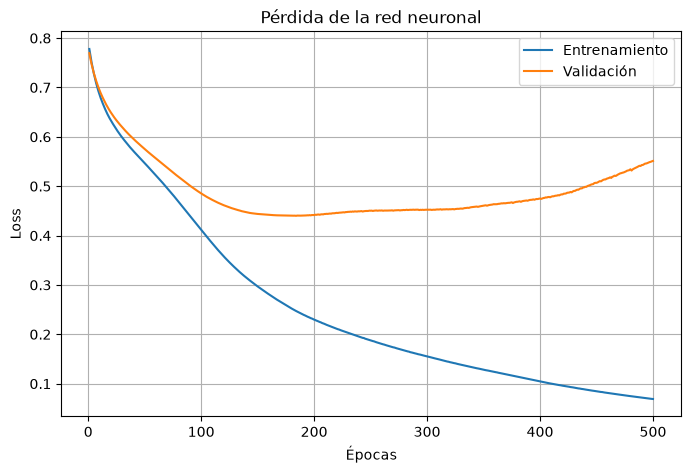

In [24]:
# Extraemos los datos del historial
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)


# Gráfica de Accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, acc, label='Entrenamiento')

plt.plot(epochs, val_acc, label='Validación')

plt.title('Accuracy de la red neuronal')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()


# Gráfica de Loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, loss, label='Entrenamiento')

plt.plot(epochs, val_loss, label='Validación')

plt.title('Pérdida de la red neuronal')
plt.xlabel('Épocas')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()